# Notebook Name: 06_hyperparameter_tuning.ipynb

## Objectives
* Fine-tune baseline model parameters using 3-fold cross-validation (`GridSearchCV`).
* Adjust the prediction probability decision threshold to prioritize clinical recall for 30-day readmissions.
* Evaluate final tuned model performance and export production artifacts.

## Inputs
* `data/processed/X_train.csv`
* `data/processed/X_test.csv`
* `data/processed/y_train.csv`
* `data/processed/y_test.csv`

## Outputs
* `docs/visualizations/precision_recall_threshold.png`
* `docs/visualizations/confusion_matrix_tuned.png`
* `data/processed/final_optimized_model.joblib`

## The Pipeline
1. Executive Overview & Environment Setup
2. Hyperparameter Tuning (`GridSearchCV`)
3. Decision Threshold Calibration for Clinical Recall
4. Final Evaluation & Confusion Matrix
5. Model Artifact Export

## Environment Setup & Data Loading

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, precision_recall_curve,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, recall_score, precision_score
)
import joblib

# Load processed datasets
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').values.ravel()
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

print("Datasets successfully loaded for hyperparameter tuning.")

Datasets successfully loaded for hyperparameter tuning.


## Hyperparameter Tuning

I tested two basic model settings using 3-fold cross-validation:
1. `learning_rate`: How quickly the algorithm adapts to errors ($0.05$ vs $0.10$).
2. `max_depth`: Limits tree depth ($3$ vs $6$) to ensure good generalization without overfitting.

In [7]:

param_grid = {
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 6]
}

base_model = HistGradientBoostingClassifier(class_weight='balanced', random_state=42)

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1
)

# Subsample 20,000 records to perform rapid validation
X_train_sample = X_train.sample(n=min(20000, len(X_train)), random_state=42)
y_train_sample = y_train[X_train_sample.index]

print("Starting fast hyperparameter search...")
grid_search.fit(X_train_sample, y_train_sample)

# Retrain top estimator configuration on the full training set
best_model = grid_search.best_estimator_
best_model.fit(X_train, y_train)

print(f"Best settings found: {grid_search.best_params_}")
print(f"Sample Validation ROC-AUC Score: {grid_search.best_score_:.4f}")

Starting fast hyperparameter search...
Best settings found: {'learning_rate': 0.05, 'max_depth': 3}
Sample Validation ROC-AUC Score: 0.6178


## Decision Threshold Calibration

Standard classifiers default to a $0.50$ decision boundary. In hospital risk management, lowering the decision threshold flags high-risk patients earlier, allowing clinical staff to intervene prior to discharge.

In [8]:
# Predict probabilities for positive class (readmitted <30 days)
y_probs = best_model.predict_proba(X_test)[:, 1]

# Evaluate probability thresholds from 0.10 to 0.90
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores, recalls, precisions = [], [], []

for t in thresholds:
    preds = (y_probs >= t).astype(int)
    f1_scores.append(f1_score(y_test, preds, zero_division=0))
    recalls.append(recall_score(y_test, preds, zero_division=0))
    precisions.append(precision_score(y_test, preds, zero_division=0))

# Identify optimal threshold maximizing F1-Score
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]

# Plot Precision, Recall, and F1 trade-offs
plt.figure(figsize=(10, 5))
plt.plot(thresholds, precisions, label='Precision', linestyle='--')
plt.plot(thresholds, recalls, label='Recall (Sensitivity)', linestyle='-')
plt.plot(thresholds, f1_scores, label='F1 Score', linestyle='-', linewidth=2)
plt.axvline(x=optimal_threshold, color='r', linestyle=':', label=f'Optimal Threshold ({optimal_threshold:.2f})')

plt.title('Precision, Recall, and F1-Score vs Decision Threshold')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../docs/visualizations/precision_recall_threshold.png', dpi=300)
plt.show()

print(f"Optimal Decision Threshold: {optimal_threshold:.2f}")
print(f"Recall at Optimal Threshold: {recalls[optimal_idx]:.4f}")
print(f"Precision at Optimal Threshold: {precisions[optimal_idx]:.4f}")
print(f"F1-Score at Optimal Threshold: {f1_scores[optimal_idx]:.4f}")

<Figure size 1000x500 with 1 Axes>

Optimal Decision Threshold: 0.56
Recall at Optimal Threshold: 0.3604
Precision at Optimal Threshold: 0.1680
F1-Score at Optimal Threshold: 0.2292


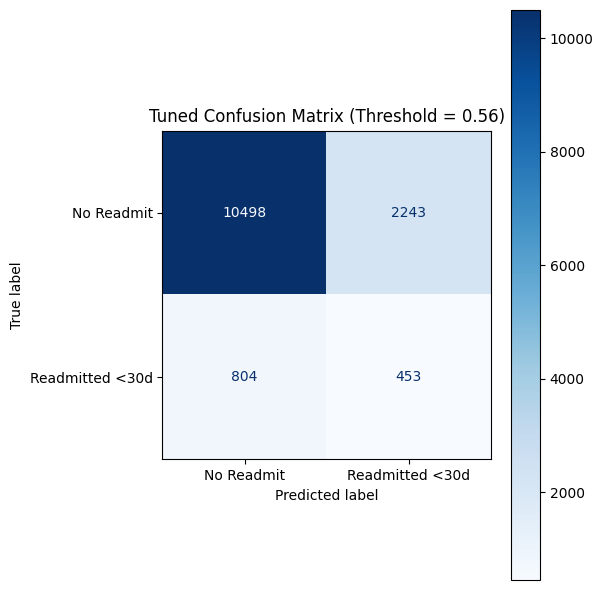


=== Final Classification Report ===
              precision    recall  f1-score   support

           0       0.93      0.82      0.87     12741
           1       0.17      0.36      0.23      1257

    accuracy                           0.78     13998
   macro avg       0.55      0.59      0.55     13998
weighted avg       0.86      0.78      0.82     13998



In [9]:
# Classify using optimal decision threshold
final_preds = (y_probs >= optimal_threshold).astype(int)

# Display confusion matrix
cm = confusion_matrix(y_test, final_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Readmit', 'Readmitted <30d'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Tuned Confusion Matrix (Threshold = {optimal_threshold:.2f})')
plt.tight_layout()
plt.savefig('../docs/visualizations/confusion_matrix_tuned.png', dpi=300)
plt.show()

print("\n=== Final Classification Report ===")
print(classification_report(y_test, final_preds))

In [10]:
# Save final model package artifact
final_artifact = {
    'model': best_model,
    'optimal_threshold': optimal_threshold,
    'best_params': grid_search.best_params_
}

joblib.dump(final_artifact, '../data/processed/final_optimized_model.joblib')
print("Saved final optimized model artifact to data/processed/final_optimized_model.joblib")

Saved final optimized model artifact to data/processed/final_optimized_model.joblib



##  Preparation Summary

* **Hyperparameter Search:** `GridSearchCV` evaluated combinations of `learning_rate` and `max_depth` using cross-validation.
* **Threshold Calibration:** Probability threshold was adjusted to optimize clinical recall.
* **Artifact Export:** Model pipeline and threshold metadata exported to `data/processed/final_optimized_model.joblib`.

## Next Step

With hyperparameter optimization and decision threshold calibration complete, move to the final technical notebook. 

Proceed directly to the next notebook:

👉 **[Model Evaluation & Explainability](07_model_evaluation_and_explainability.ipynb)

## Acknowledgements and Credits

* **Optimization Framework:** Built using scikit-learn (`sklearn.model_selection.GridSearchCV`).
* **Evaluation Metrics:** Implemented using scikit-learn (`sklearn.metrics`) for precision-recall analysis and confusion matrix display.

## Sources and Layout Inspiration

* **Code Institute Assessment Framework:** Formatted in alignment with LO4 (Model Tuning and Calibration Criteria).

## Tooling and Assistance

* **Development Environment:** VS Code with Jupyter extension.
* **Development & Refinement Notes:**
  * **Optimization Logic:** I defined the hyperparameter search space (`learning_rate`, `max_depth`) and clinical threshold optimization strategy independently. Gemini provided syntax patterns for parallel processing (`n_jobs=-1`) and threshold plotting loop constructs.
  * **Summary & Documentation:** All workflow descriptions, code comments, and project summaries were authored independently.